In [ ]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
from sklearn.model_selection import StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

# Same project structure as 04_preprocessing.ipynb
try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/hotel-booking-cancellation')
except ImportError:
    ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / 'data/splits/X_train.csv').exists()
    )

SPLIT_DIR = ROOT / 'data/splits'
MODEL_DIR = ROOT / 'models'
REPORT_DIR = ROOT / 'reports/random_forest'
REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
CV_FOLDS = 5

print("Project root:", ROOT)
print("Split directory:", SPLIT_DIR)
print("Model directory:", MODEL_DIR)

Mounted at /content/drive
Project root: /content/drive/MyDrive/hotel-booking-cancellation
Split directory: /content/drive/MyDrive/hotel-booking-cancellation/data/splits
Model directory: /content/drive/MyDrive/hotel-booking-cancellation/models


In [ ]:
# Load the exact split generated by 04_preprocessing.ipynb
X_train = pd.read_csv(SPLIT_DIR / 'X_train.csv', dtype={'agent': str})
X_test = pd.read_csv(SPLIT_DIR / 'X_test.csv', dtype={'agent': str})
y_train = pd.read_csv(SPLIT_DIR / 'y_train.csv')['is_canceled']
y_test = pd.read_csv(SPLIT_DIR / 'y_test.csv')['is_canceled']

# Load the exact UNFITTED preprocessor saved by 04_preprocessing.ipynb
shared_preprocessor = joblib.load(
    MODEL_DIR / 'preprocessor_unfitted.joblib'
)

# Load the preprocessing configuration for documentation/checking
config_path = MODEL_DIR / 'preprocessing_config.json'
if config_path.exists():
    preprocessing_config = json.loads(config_path.read_text())
else:
    preprocessing_config = {}

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)
print("\nPreprocessor:", type(shared_preprocessor).__name__)
print("Preprocessing config:")
print(json.dumps(preprocessing_config, indent=2)[:4000])

X_train: (69777, 28)
X_test : (17445, 28)
y_train: (69777,)
y_test : (17445,)

Preprocessor: ColumnTransformer
Preprocessing config:
{
  "source_feature_dataset": "/content/drive/MyDrive/hotel-booking-cancellation/data/processed/hotel_bookings_features.csv",
  "target": "is_canceled",
  "random_state": 42,
  "test_size": 0.2,
  "stratified": true,
  "numerical_features": [
    "lead_time",
    "arrival_date_year",
    "arrival_date_week_number",
    "arrival_date_day_of_month",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "adr",
    "required_car_parking_spaces",
    "total_of_special_requests",
    "total_stay",
    "total_guests"
  ],
  "binary_features": [
    "is_repeated_guest",
    "is_family"
  ],
  "categorical_features": [
    "hotel",
    "arrival_date_month",
    "meal",
    "country",
    "market_segment",
    "distribution_channel",
    "reserve

In [ ]:
NUMERICAL_FEATURES = [
    'lead_time',
    'arrival_date_year',
    'arrival_date_week_number',
    'arrival_date_day_of_month',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'babies',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests',
    'total_stay',
    'total_guests',
]

BINARY_FEATURES = [
    'is_repeated_guest',
    'is_family',
]

CATEGORICAL_FEATURES = [
    'hotel',
    'arrival_date_month',
    'meal',
    'country',
    'market_segment',
    'distribution_channel',
    'reserved_room_type',
    'deposit_type',
    'customer_type',
    'agent',
]

# Combine all approved features
APPROVED_FEATURES = (
    NUMERICAL_FEATURES
    + BINARY_FEATURES
    + CATEGORICAL_FEATURES
)

# ---------------------------------------------------------
# Check that X_train contains exactly the approved features
# ---------------------------------------------------------

assert set(X_train.columns) == set(APPROVED_FEATURES), (
    "X_train columns do not match the approved feature set."
)

# ---------------------------------------------------------
# Check that X_test contains exactly the approved features
# ---------------------------------------------------------

assert set(X_test.columns) == set(APPROVED_FEATURES), (
    "X_test columns do not match the approved feature set."
)

# ---------------------------------------------------------
# Reorder columns to the approved preprocessing order
# ---------------------------------------------------------

X_train = X_train[APPROVED_FEATURES]
X_test = X_test[APPROVED_FEATURES]

# ---------------------------------------------------------
# Final verification
# ---------------------------------------------------------

assert list(X_train.columns) == APPROVED_FEATURES
assert list(X_test.columns) == APPROVED_FEATURES

print("Feature groups match the preprocessing notebook.")
print()
print("Total approved predictors:", len(APPROVED_FEATURES))
print("Numerical:", len(NUMERICAL_FEATURES))
print("Binary:", len(BINARY_FEATURES))
print("Categorical:", len(CATEGORICAL_FEATURES))
print()
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print()
print("Column order has been aligned with the preprocessing configuration.")

Feature groups match the preprocessing notebook.

Total approved predictors: 28
Numerical: 16
Binary: 2
Categorical: 10

X_train shape: (69777, 28)
X_test shape: (17445, 28)

Column order has been aligned with the preprocessing configuration.


In [ ]:
print("Training target distribution:")
display(y_train.value_counts().rename_axis("is_canceled").to_frame("count"))

print("\nTraining target percentages:")
display((y_train.value_counts(normalize=True) * 100).round(2).rename_axis("is_canceled").to_frame("percentage"))

print("\nTest target percentages:")
display((y_test.value_counts(normalize=True) * 100).round(2).rename_axis("is_canceled").to_frame("percentage"))

assert len(X_train) == len(y_train)
assert len(X_test) == len(y_test)
assert "is_canceled" not in X_train.columns
assert "is_canceled" not in X_test.columns

Training target distribution:


,count
is_canceled,
0,50570
1,19207



Training target percentages:


,percentage
is_canceled,
0,72.47
1,27.53



Test target percentages:


,percentage
is_canceled,
0,72.47
1,27.53


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

SCORING = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

print(cv)
print("Metrics:", list(SCORING.keys()))

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Metrics: ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


In [9]:
baseline_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    class_weight=None
)

baseline_pipeline = Pipeline([
    ("preprocess", clone(shared_preprocessor)),
    ("model", baseline_rf)
])

print(baseline_pipeline)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['lead_time',
                                                   'arrival_date_year',
                                                   'arrival_date_week_number',
                                                   'arrival_date_day_of_month',
                                                   'stays_in_weekend_nights',
                                                   'stays_in_week_nights',
                                                   'adults', 'children',
                                              

In [8]:
# Baseline Stratified 5-Fold CV
baseline_cv = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=SCORING,
    n_jobs=-1,
    return_train_score=True
)

baseline_cv_summary = pd.DataFrame({
    "metric": ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"],
    "CV Mean": [
        baseline_cv["test_accuracy"].mean(),
        baseline_cv["test_precision"].mean(),
        baseline_cv["test_recall"].mean(),
        baseline_cv["test_f1"].mean(),
        baseline_cv["test_roc_auc"].mean(),
    ],
    "CV Std": [
        baseline_cv["test_accuracy"].std(),
        baseline_cv["test_precision"].std(),
        baseline_cv["test_recall"].std(),
        baseline_cv["test_f1"].std(),
        baseline_cv["test_roc_auc"].std(),
    ],
    "Train Mean": [
        baseline_cv["train_accuracy"].mean(),
        baseline_cv["train_precision"].mean(),
        baseline_cv["train_recall"].mean(),
        baseline_cv["train_f1"].mean(),
        baseline_cv["train_roc_auc"].mean(),
    ]
})

baseline_cv_summary

,metric,CV Mean,CV Std,Train Mean
0,Accuracy,0.846669,0.001774,0.997324
1,Precision,0.763744,0.004630,0.997346
2,Recall,0.641432,0.008166,0.992919
3,F1,0.697223,0.004670,0.995128
4,ROC-AUC,0.906261,0.000928,0.999952


### 1. Fit the Baseline Pipeline on the Entire Training Dataset and Evaluate on the Test Set
Now we will train the full baseline pipeline on all of `X_train` and evaluate its performance against the holdout `X_test` dataset.

In [ ]:
# Fit baseline pipeline on entire training data
baseline_pipeline.fit(X_train, y_train)

# Make predictions on test set
y_pred = baseline_pipeline.predict(X_test)
y_pred_proba = baseline_pipeline.predict_proba(X_test)[:, 1]

# Calculate metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_pred_proba)
}

test_metrics_df = pd.DataFrame(list(test_metrics.items()), columns=["Metric", "Test Value"])
display(test_metrics_df)

,Metric,Test Value
0,Accuracy,0.850043
1,Precision,0.768024
2,Recall,0.652228
3,F1,0.705405
4,ROC-AUC,0.910997


### 2. Visualize Model Performance
We will visualize the confusion matrix and print the detailed classification report.

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.90     12643
           1       0.77      0.65      0.71      4802

    accuracy                           0.85     17445
   macro avg       0.82      0.79      0.80     17445
weighted avg       0.85      0.85      0.85     17445



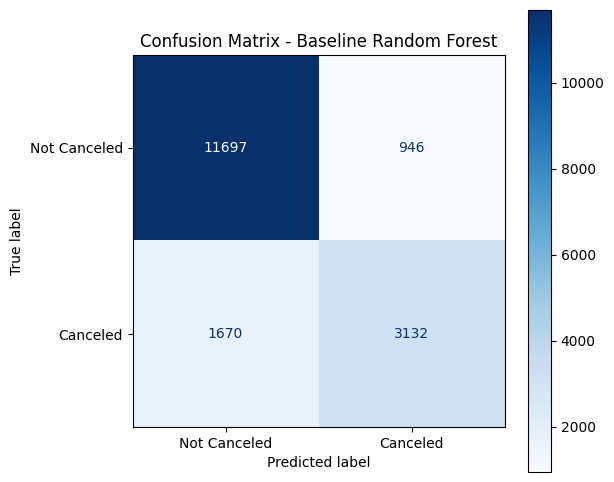

In [ ]:
# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not Canceled", "Canceled"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", ax=ax)
plt.title("Confusion Matrix - Baseline Random Forest")
plt.show()

### 3. Save the Baseline Model and Report
We will save the fitted baseline pipeline and export the evaluation metrics to our reports folder.

In [ ]:
# Save the pipeline
joblib.dump(baseline_pipeline, MODEL_DIR / 'baseline_random_forest.joblib')

# Save the evaluation metrics as a JSON report
metrics_to_save = {metric: float(val) for metric, val in test_metrics.items()}
with open(REPORT_DIR / 'baseline_evaluation.json', 'w') as f:
    json.dump(metrics_to_save, f, indent=4)

print("Model saved to:", MODEL_DIR / 'baseline_random_forest.joblib')
print("Report saved to:", REPORT_DIR / 'baseline_evaluation.json')

Model saved to: /content/drive/MyDrive/hotel-booking-cancellation/models/baseline_random_forest.joblib
Report saved to: /content/drive/MyDrive/hotel-booking-cancellation/reports/random_forest/baseline_evaluation.json


### 4. Hyperparameter Tuning using RandomizedSearchCV
We will define a parameter grid for our `RandomForestClassifier` and use `RandomizedSearchCV` combined with our stratified cross-validation setup (`cv`) to search for the best hyperparameters.

In [10]:
# Define the hyperparameter search space
# Note the prefix 'model__' to target the RandomForestClassifier step in our pipeline
param_distributions = {
    'model__n_estimators': [100, 200, 300, 500],
    'model__max_depth': [10, 20, 30, None],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
    'model__max_features': ['sqrt', 'log2', None],
    'model__class_weight': [None, 'balanced', 'balanced_subsample']
}

# Set up RandomizedSearchCV
tuned_rf_search = RandomizedSearchCV(
    estimator=baseline_pipeline,
    param_distributions=param_distributions,
    n_iter=10,  # Number of parameter settings sampled (adjust as needed for time/compute)
    cv=cv,
    scoring='f1',  # Optimize for F1-score, or choose another metric like 'roc_auc'
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=1
)

print("Hyperparameter search configured.")
print("To start tuning, run: tuned_rf_search.fit(X_train, y_train)")

Hyperparameter search configured.
To start tuning, run: tuned_rf_search.fit(X_train, y_train)


In [ ]:
# Fit the hyperparameter search on the training data
tuned_rf_search.fit(X_train, y_train)

# Extract and print the best parameters and score
print("Best parameters found:")
print(tuned_rf_search.best_params_)
print(f"\nBest cross-validation F1-score: {tuned_rf_search.best_score_:.4f}")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters found:
{'model__n_estimators': 300, 'model__min_samples_split': 10, 'model__min_samples_leaf': 4, 'model__max_features': None, 'model__max_depth': None, 'model__class_weight': 'balanced_subsample'}

Best cross-validation F1-score: 0.7240


In [ ]:
# Convert cross-validation results to a DataFrame for comparison
cv_results_df = pd.DataFrame(tuned_rf_search.cv_results_)

# Select key columns to compare performance across configurations
comparison_cols = [
    'rank_test_score',
    'mean_test_score',
    'std_test_score',
    'param_model__n_estimators',
    'param_model__max_depth',
    'param_model__min_samples_split',
    'param_model__min_samples_leaf',
    'param_model__max_features',
    'param_model__class_weight'
]

# Rename columns for cleaner display
comparison_df = cv_results_df[comparison_cols].sort_values(by='rank_test_score')
comparison_df.columns = [
    'Rank', 'Mean CV F1', 'Std CV F1',
    'n_estimators', 'max_depth', 'min_samples_split',
    'min_samples_leaf', 'max_features', 'class_weight'
]

print("Hyperparameter Tuning Results Comparison:")
display(comparison_df)

### 5. Save the Best Tuned Model and Configuration
We will save the best pipeline estimator found by our hyperparameter search and export the selected parameters to our reports folder.

In [ ]:
# Retrieve the best pipeline model found during the search
best_tuned_pipeline = tuned_rf_search.best_estimator_

# Save the best model pipeline to the models directory
joblib.dump(best_tuned_pipeline, MODEL_DIR / 'random_forest_tuned.joblib')

# Convert best parameters to a JSON-serializable format (handling None values correctly)
best_params_serializable = {
    str(k): (v if v is not None else "None") for k, v in tuned_rf_search.best_params_.items()
}

# Save the best parameters config to the reports folder
with open(REPORT_DIR / 'best_hyperparameters.json', 'w') as f:
    json.dump(best_params_serializable, f, indent=4)

print("Best model saved to:", MODEL_DIR / 'tuned_random_forest.joblib')
print("Best parameters saved to:", REPORT_DIR / 'best_hyperparameters.json')